<a href="https://colab.research.google.com/github/AHMAD75REZA/AHMAD75REZA/blob/main/CIFAR100_ABT_journal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CIFAR-100 experiments for the TNNLS paper: ABT + contribution-sign check under real masking

This notebook is **new** and separate from `Copy_of_CIFAR100V4.ipynb` (the Wiley-paper record, left untouched).
It reuses that notebook's data loading, ResNet-18 (GroupNorm), local training, collinear masking and the
collinear-mask attack, and adds:

* **ABT** (Adaptive Bayesian Trust): `defense='abt'`, same filter and defaults as the simulator (beta = 0.5).
* **Contribution-sign check**: `sign_check=True`. AS computes <A2, A1> and MS computes <A3, A1> per chunk;
  only the bit [<A2,A1> > <A3,A1>] is used (in deployment this is a two-party secure comparison).
* **FedCon-DefendFL without the confidence cap** (`conf_cap=False`), as described in DefendFL and in our paper.
* Per-round logging of the weight given to attackers, benign users excluded and the time of each component.
* A **new results folder**, so nothing in the old folder is touched. Every run resumes from its checkpoint.

**Runtime:** about 60 s per round on the RTX A2000, i.e. about 1.7 h per 100-round run.
Phase 1 = 18 runs (about 31 h), Phase 2 = 12 runs (about 20 h). Run the cells top to bottom; the run
cells can be stopped and restarted at any time.

In [ ]:
# ===== Cell 1: imports, environment detection, device =====
import os, sys, time, json, math, glob, pickle, tarfile, hashlib, random, tempfile
from dataclasses import dataclass, field, asdict
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# Optional: if this GPU workstation is shared, uncomment and pick a specific GPU index
# BEFORE any torch.cuda call, e.g. to use only the second GPU:
# os.environ['CUDA_VISIBLE_DEVICES'] = '1'

# Detect whether we are really inside Google Colab (with Drive available) or a plain/local
# Jupyter kernel (a remote-desktop GPU workstation, a department server, etc). On a local
# kernel `google.colab` simply is not importable, so this falls through safely with no error.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    print('Running inside Google Colab with Drive mounted.')
except ImportError:
    IN_COLAB = False
    print('Running as a local/remote Jupyter kernel (no Google Colab, no Drive mount needed).')

DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', DEV)
if DEV.type == 'cuda':
    for i in range(torch.cuda.device_count()):
        p = torch.cuda.get_device_properties(i)
        mark = ' <- current' if i == torch.cuda.current_device() else ''
        print(f'  GPU {i}: {p.name}  ({p.total_memory / 1e9:.1f} GB){mark}')
    torch.backends.cudnn.benchmark = True   # inputs are fixed-size (32x32), so this speeds up convs
else:
    print('  !! No GPU detected. Training will be extremely slow on CPU.')
    print('     Check that this Jupyter kernel is the one connected to the GPU workstation,')
    print('     and that `torch` was installed with CUDA support matching the GPU driver.')


Running as a local/remote Jupyter kernel (no Google Colab, no Drive mount needed).
torch 2.14.0+cu126 | device: cuda
  GPU 0: NVIDIA RTX A2000 12GB  (12.1 GB) <- current


In [ ]:
# ===== Cell 2: paths and configuration (new: ABT, sign check, uncapped FedCon) =====
# Plain local paths on the GPU workstation's disk - no Google Drive involved.
# Windows example (raw string, backslashes OK): r"C:\Users\Ahmad\Desktop\Implementation\Datasets\CIFAR-100"
# Linux/remote-desktop example: "/home/ahmad/data/CIFAR-100"
DATA_DIR = r"C:\Users\Ahmad\Desktop\Implementation\Datasets\CIFAR-100"   # <-- EDIT: folder holding your CIFAR-100 files
OUT_DIR  = r"C:\Users\Ahmad\Desktop\Implementation\Results\ABT_journal_CIFAR100"  # <-- NEW folder (old results stay untouched)
os.makedirs(OUT_DIR, exist_ok=True)

NUM_CLASSES = 100


@dataclass
class Cfg:
    run_name: str = 'run'
    data_dir: str = DATA_DIR
    out_dir: str = OUT_DIR
    # ---- model / FL ----
    arch: str = 'resnet18'          # 'resnet18' (GroupNorm) | 'smallcnn' (paper-like CNN)
    n_users: int = 20
    rounds: int = 100
    local_epochs: int = 2
    batch_size: int = 64
    lr: float = 0.05                # local lr at round 1, cosine-decayed across rounds
    lr_min: float = 0.002
    momentum: float = 0.9
    weight_decay: float = 5e-4
    label_smoothing: float = 0.0
    server_lr: float = 1.0          # 1.0 == plain FedAvg (W <- W - mean(delta))
    server_momentum: float = 0.0
    partition: str = 'iid'          # 'iid' | 'dirichlet'
    dir_alpha: float = 0.5
    # ---- attack ----
    mal_frac: float = 0.25          # fraction of malicious users (paper: 25%; <50% by the threat model)
    mask_attacker_share: float = 0.5  # share of malicious users that use mask-based attacks
    grad_attack: str = 'labelflip'  # gradient-based: labelflip | signflip | noise | scale | backdoor
    mask_payload: str = 'labelflip' # poisonous gradient g_bar injected by mask-based attackers (same options)
    mask_attack_types: tuple = (1, 2, 3)  # 1: poisonous A2, 2: poisonous A3, 3: poisonous A3 + forged A1 sent to MS
    poison_rate: float = 0.5        # fraction of a malicious user's samples that are poisoned (labelflip/backdoor)
    attack_scale: float = 5.0       # strength for signflip / scale / noise
    backdoor_target: int = 0
    attack_start: int = 6           # round in which attackers start (paper: 6)
    # ---- defence ----
    defense: str = 'defendfl_con'   # none | defendfl_avg | defendfl_con | abt | krum | median | trimmed_mean
    defense_start: int = 6
    num_chunks: int = 8             # N in g = g(1)||...||g(N); each chunk gets its own random mask scalars
    lam_max: float = 10.0           # mask scalars are drawn from (0.5, lam_max) / (1.5, lam_max)
    range_N: float = 100.0          # public element range (-N, N) that every masked value must respect
    coll_eps: float = 1e-4          # collinearity tolerance (relative residual)
    sim_c: float = 2.5              # flag user if Sim_i < median - max(sim_c*1.4826*MAD, sim_min_gap)
    sim_min_gap: float = 0.02
    verify_commitment: bool = True
    check_collinearity: bool = True
    check_similarity: bool = True
    conf_init: float = 100.0        # paper: initial confidence 100
    conf_dec: float = 5.0           # paper: -5 for malicious
    conf_inc: float = 1.0           # paper: +1 for benign
    conf_mode: str = 'detector'     # 'detector' (uses DefendFL's own detection) | 'oracle' (paper-style, uses ground truth)
    conf_cap: bool = False          # NEW: False = confidence can grow above conf_init (DefendFL's rule, as in our paper)
    # ---- NEW: contribution-sign check ----
    sign_check: bool = False        # True: users with <A2,A1> <= <A3,A1> in any chunk fail verification
    # ---- NEW: ABT (Adaptive Bayesian Trust), same defaults as the simulator ----
    abt_b0: float = 0.1
    abt_qa: float = 0.02
    abt_qr: float = 0.02
    abt_beta: float = 0.5
    abt_eps: float = 1e-4
    abt_mu: float = 0.3
    abt_theta: float = 0.5
    abt_zmax: float = 10.0
    abt_L: float = 12.0
    # ---- misc ----
    seed: int = 0
    use_amp: bool = True
    ckpt_every: int = 5
    resume: bool = True


AMP = False  # set per run

In [ ]:
# ===== Cell 3: data loading + preprocessing =====
CIFAR100_MEAN = (0.5071, 0.4865, 0.4409)
CIFAR100_STD = (0.2673, 0.2564, 0.2762)


def _unpickle(path):
    with open(path, 'rb') as f:
        return pickle.load(f, encoding='latin1')


def _find_pickle_dir(root):
    for p in glob.glob(os.path.join(root, '**', 'train'), recursive=True):
        d = os.path.dirname(p)
        if os.path.isfile(p) and os.path.isfile(os.path.join(d, 'test')):
            return d
    return None


def _load_image_folders(root):
    """Fallback for PNG/JPG folders: root/**/train/<class>/*.png and root/**/test/<class>/*.png"""
    from PIL import Image
    from torchvision.datasets import ImageFolder
    tr = te = None
    for p in glob.glob(os.path.join(root, '**', 'train'), recursive=True):
        if os.path.isdir(p) and os.path.isdir(os.path.join(os.path.dirname(p), 'test')):
            tr, te = p, os.path.join(os.path.dirname(p), 'test')
            break
    if tr is None:
        return None

    def read(path):
        ds = ImageFolder(path)
        xs, ys = [], []
        for fp, lab in ds.samples:
            im = Image.open(fp).convert('RGB')
            if im.size != (32, 32):
                im = im.resize((32, 32))
            xs.append(np.asarray(im, dtype=np.uint8).transpose(2, 0, 1))
            ys.append(lab)
        return np.stack(xs), np.array(ys)
    return read(tr) + read(te)


def load_cifar100(data_dir):
    """Returns uint8 tensors on DEV: Xtr (N,3,32,32), Ytr (N,), Xte, Yte."""
    d = _find_pickle_dir(data_dir)
    if d is None:  # maybe it is still a tar.gz -> extract to local disk (faster than Drive)
        for t in glob.glob(os.path.join(data_dir, '**', '*.tar*'), recursive=True):
            if 'cifar-100' in os.path.basename(t).lower():
                dst = os.path.join(tempfile.gettempdir(), 'cifar100_extracted')  # works on Windows and Linux
                os.makedirs(dst, exist_ok=True)
                print('extracting', t)
                with tarfile.open(t) as tf:
                    tf.extractall(dst)
                d = _find_pickle_dir(dst)
                break
    if d is not None:
        tr, te = _unpickle(os.path.join(d, 'train')), _unpickle(os.path.join(d, 'test'))
        Xtr = np.asarray(tr['data'], dtype=np.uint8).reshape(-1, 3, 32, 32)   # already CHW, RGB
        Ytr = np.asarray(tr['fine_labels'], dtype=np.int64)
        Xte = np.asarray(te['data'], dtype=np.uint8).reshape(-1, 3, 32, 32)
        Yte = np.asarray(te['fine_labels'], dtype=np.int64)
    else:
        out = _load_image_folders(data_dir)
        if out is None:
            raise FileNotFoundError(
                f'No CIFAR-100 found under {data_dir}. Expected cifar-100-python/ (train, test, meta), '
                'a cifar-100-python.tar.gz, or train/ and test/ image folders.')
        Xtr, Ytr, Xte, Yte = out
    # ---- sanity checks ----
    assert Xtr.shape == (50000, 3, 32, 32) and Xte.shape == (10000, 3, 32, 32), (Xtr.shape, Xte.shape)
    assert Ytr.min() == 0 and Ytr.max() == 99, 'labels must be 0..99'
    print(f'CIFAR-100 loaded: train {Xtr.shape}, test {Xte.shape}, '
          f'per-class train min/max = {np.bincount(Ytr).min()}/{np.bincount(Ytr).max()}')
    t = lambda a: torch.from_numpy(a).to(DEV)
    return t(Xtr), t(Ytr), t(Xte), t(Yte)


_MEAN = torch.tensor(CIFAR100_MEAN, device=DEV).view(1, 3, 1, 1)
_STD = torch.tensor(CIFAR100_STD, device=DEV).view(1, 3, 1, 1)


def normalize(x01):
    return (x01 - _MEAN) / _STD


def prep_eval(xb_uint8):
    """Test-time preprocessing: scale to [0,1] and normalise only (no augmentation)."""
    return normalize(xb_uint8.float() / 255.)


def augment(xb):
    """Train-time preprocessing on GPU: random crop (pad 4) + horizontal flip + normalise."""
    B, dev = xb.size(0), xb.device
    x = F.pad(xb.float() / 255., (4, 4, 4, 4))
    i = torch.randint(0, 9, (B,), device=dev)
    j = torch.randint(0, 9, (B,), device=dev)
    ar = torch.arange(32, device=dev)
    rows = (i[:, None] + ar)[:, None, :, None]
    cols = (j[:, None] + ar)[:, None, None, :]
    x = x[torch.arange(B, device=dev)[:, None, None, None],
          torch.arange(3, device=dev)[None, :, None, None], rows, cols]
    flip = torch.rand(B, device=dev) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    return normalize(x)


def partition(labels_np, n_users, mode, alpha, seed):
    rng = np.random.default_rng(seed)
    n = len(labels_np)
    if mode == 'iid':
        return [torch.as_tensor(a) for a in np.array_split(rng.permutation(n), n_users)]
    for _ in range(200):
        parts = [[] for _ in range(n_users)]
        for c in range(NUM_CLASSES):
            idc = np.where(labels_np == c)[0]
            rng.shuffle(idc)
            p = rng.dirichlet(alpha * np.ones(n_users))
            cuts = (np.cumsum(p) * len(idc)).astype(int)[:-1]
            for u, ch in enumerate(np.split(idc, cuts)):
                parts[u] += ch.tolist()
        if min(len(p) for p in parts) >= 50:
            break
    return [torch.as_tensor(np.array(p, dtype=np.int64)) for p in parts]

In [ ]:
# ===== Cell 4: models and flat-vector helpers =====
def gn(c):
    return nn.GroupNorm(min(8, c), c)   # GroupNorm: no running statistics, so "gradient = weight delta" is well defined


class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.n1 = gn(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.n2 = gn(cout)
        self.sc = None
        if stride != 1 or cin != cout:
            self.sc = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), gn(cout))

    def forward(self, x):
        o = F.relu(self.n1(self.c1(x)))
        o = self.n2(self.c2(o))
        return F.relu(o + (x if self.sc is None else self.sc(x)))


class ResNet18GN(nn.Module):
    """ResNet-18 for 32x32 inputs: 3x3 stem, no max-pool, GroupNorm."""
    def __init__(self, nc=100):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 64, 3, 1, 1, bias=False), gn(64), nn.ReLU())
        plan = [(64, 64, 1), (64, 64, 1), (64, 128, 2), (128, 128, 1),
                (128, 256, 2), (256, 256, 1), (256, 512, 2), (512, 512, 1)]
        self.blocks = nn.Sequential(*[BasicBlock(a, b, s) for a, b, s in plan])
        self.fc = nn.Linear(512, nc)

    def forward(self, x):
        x = self.blocks(self.stem(x))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))


def small_cnn(nc=100):
    """Paper-style CNN: 3 conv layers, 1 max-pool, 3 fully connected layers."""
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
        nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
        nn.MaxPool2d(4), nn.Flatten(),
        nn.Linear(128 * 8 * 8, 512), nn.ReLU(),
        nn.Linear(512, 256), nn.ReLU(),
        nn.Linear(256, nc))


def build_model(arch):
    return (ResNet18GN(NUM_CLASSES) if arch == 'resnet18' else small_cnn(NUM_CLASSES)).to(DEV)


def get_vec(model):
    return torch.cat([p.detach().reshape(-1) for p in model.parameters()])


def set_vec(model, vec):
    i = 0
    with torch.no_grad():
        for p in model.parameters():
            n = p.numel()
            p.copy_(vec[i:i + n].view_as(p))
            i += n


@torch.no_grad()
def evaluate(model, vec, X, Y, target=None, bs=1000):
    """Top-1, top-5 and (optionally) backdoor attack-success-rate."""
    set_vec(model, vec); model.eval()
    c1 = c5 = 0
    for s in range(0, X.size(0), bs):
        with torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=AMP):
            out = model(prep_eval(X[s:s + bs]))
        top5 = out.topk(5, 1).indices
        y = Y[s:s + bs]
        c1 += (top5[:, 0] == y).sum().item()
        c5 += (top5 == y[:, None]).any(1).sum().item()
    res = dict(acc=100. * c1 / X.size(0), top5=100. * c5 / X.size(0))
    if target is not None:
        keep = Y != target
        Xb = X[keep].clone()
        Xb[:, :, -4:-1, -4:-1] = 255
        hit = 0
        for s in range(0, Xb.size(0), bs):
            with torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=AMP):
                pred = model(prep_eval(Xb[s:s + bs])).argmax(1)
            hit += (pred == target).sum().item()
        res['asr'] = 100. * hit / Xb.size(0)
    return res

In [ ]:
# ===== Cell 5: local training and (gradient-level) attacks =====
TRAIN_POISON = ('labelflip', 'backdoor')   # attacks that change the training data


def make_scaler(enabled):
    try:
        return torch.amp.GradScaler('cuda', enabled=enabled)
    except AttributeError:
        return torch.cuda.amp.GradScaler(enabled=enabled)


def local_train(cfg, model, global_vec, xu, yu, lr, poison=None):
    """Train from the global weights; returns g = W_global - W_local (the 'gradient' g_i of the paper)."""
    set_vec(model, global_vec); model.train()
    n = xu.size(0); x, y = xu, yu
    if poison == 'labelflip':                       # y -> (y+1) mod 100 on a fraction of samples
        y = yu.clone(); m = torch.rand(n, device=xu.device) < cfg.poison_rate
        y[m] = (y[m] + 1) % NUM_CLASSES
    elif poison == 'backdoor':                      # 3x3 white patch near bottom-right corner -> target class
        x = xu.clone(); y = yu.clone(); m = torch.rand(n, device=xu.device) < cfg.poison_rate
        x[m, :, -4:-1, -4:-1] = 255; y[m] = cfg.backdoor_target
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=cfg.momentum, weight_decay=cfg.weight_decay)
    scaler = make_scaler(AMP)
    for _ in range(cfg.local_epochs):
        perm = torch.randperm(n, device=x.device)
        for s in range(0, n, cfg.batch_size):
            idx = perm[s:s + cfg.batch_size]
            if idx.numel() < 2:
                continue
            with torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=AMP):
                loss = F.cross_entropy(model(augment(x[idx])), y[idx], label_smoothing=cfg.label_smoothing)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update()
    return global_vec - get_vec(model)


def craft_from_honest(g, kind, cfg):
    """Poisonous gradients that are derived from the honest gradient (no extra training)."""
    if kind == 'signflip':
        return -cfg.attack_scale * g
    if kind == 'scale':
        return cfg.attack_scale * g
    if kind == 'noise':
        z = torch.randn_like(g)
        return z * (g.norm() / z.norm()) * cfg.attack_scale
    raise ValueError(kind)

In [ ]:
# ===== Cell 6: DefendFL protocol (users, AS, MS) - unchanged from the old notebook =====
def tick():
    if DEV.type == 'cuda':
        torch.cuda.synchronize()
    return time.perf_counter()


def sha(t):
    """SHA-256 commitment of a tensor (the paper uses MD5; SHA-256 is collision resistant)."""
    return hashlib.sha256(t.detach().float().cpu().numpy().tobytes()).hexdigest()


def make_mask(g, bounds, sizes, cfg):
    """Collinear mask, O(k) implementation of A2 = g P and A3 = g P' with P' = P - I.
    With P = diag(lam2): A1 = lam1*g, A2 = lam2*g, A3 = A2 - g = (lam2-1)*g.
    lam2 > 1 is required so that A3 keeps the direction of A1 (the servers test ratio > 0).
    One (lam1, lam2) pair per chunk; chunks realise g = g(1)||...||g(N)."""
    Nc = len(sizes)
    lam1 = 0.5 + (cfg.lam_max - 0.5) * torch.rand(Nc, device=g.device)
    lam2 = 1.5 + (cfg.lam_max - 1.5) * torch.rand(Nc, device=g.device)
    s1 = torch.repeat_interleave(lam1, sizes)
    s2 = torch.repeat_interleave(lam2, sizes)
    A1 = g * s1
    A2 = g * s2
    A3 = A2 - g
    return A1, A2, A3


def build_messages(g, g_bar, mtype, cfg, bounds, sizes):
    """What one user sends. g_bar is None for honest users (and gradient-based attackers, whose poison is inside g)."""
    A1, A2, A3 = make_mask(g, bounds, sizes, cfg)
    A1_ms = A1
    if g_bar is not None:
        if mtype == 1:      # poisonous masked gradient: AS computes A2_bar - A3 = g_bar
            A2 = A3 + g_bar
        elif mtype == 2:    # poisonous mask: AS computes A2 - A3_bar = g_bar
            A3 = A2 - g_bar
        elif mtype == 3:    # like 2, but also sends MS a forged A1 that is collinear with the poisonous A3
            A3 = A2 - g_bar
            A1_ms = A3.clone()
    return dict(A1=A1, A2=A2, A1_ms=A1_ms, A3=A3, commit=sha(A1))   # commitment is to the A1 sent to AS


def collinear(a, b, bounds, cfg):
    """Chunk-wise version of the paper's test A/B = lambda > 0, implemented with a robust residual test:
    lam = <a,b>/<a,a> must be > 0 and ||b - lam*a|| <= eps*||b||. Also enforces the public range (-N, N)."""
    if not (torch.isfinite(a).all() and torch.isfinite(b).all()):
        return False
    if a.abs().max() >= cfg.range_N or b.abs().max() >= cfg.range_N:
        return False
    for c in range(len(bounds) - 1):
        x = a[bounds[c]:bounds[c + 1]].double(); y = b[bounds[c]:bounds[c + 1]].double()
        xx, yy = x.dot(x).item(), y.dot(y).item()
        if xx == 0 and yy == 0:
            continue
        if xx == 0 or yy == 0:
            return False
        lam = x.dot(y).item() / xx
        if lam <= 0 or (y - lam * x).norm().item() > cfg.coll_eps * math.sqrt(yy):
            return False
    return True


def similarity_scores(vecs, bounds):
    """Sim_i = mean over other users j of the mean over chunks of cos(A1_i, A1_j)  (paper's Sim_i formula, chunk-averaged)."""
    n, Nc = len(vecs), len(bounds) - 1
    cos = torch.zeros(n, n, device=vecs[0].device)
    for c in range(Nc):
        M = F.normalize(torch.stack([v[bounds[c]:bounds[c + 1]] for v in vecs]), dim=1)
        cos += M @ M.T
    cos /= Nc
    return (cos.sum(1) - cos.diag()) / (n - 1)


def norm_weights(U2, tau):
    t = np.array([tau[u] for u in U2], dtype=float)
    if t.sum() <= 1e-12:
        t = np.ones(len(U2))
    return dict(zip(U2, t / t.sum()))


def defendfl_aggregate(msgs, cfg, bounds, conf, active):
    """One DefendFL aggregation round. Returns (aggregated gradient or None, info dict).
    'active' False (or defense == 'none') -> same message flow but no checks (plain mask-based secure aggregation)."""
    as_view = {u: (m['A1'], m['A2']) for u, m in msgs.items()}          # what AS receives
    ms_view = {u: (m['A1_ms'], m['A3']) for u, m in msgs.items()}       # what MS receives
    board = {u: m['commit'] for u, m in msgs.items()}                   # public commitments
    uids = sorted(msgs)
    info = dict(U1=[], U2=[], flagged=[], sims={}, t_detect=0., t_agg=0.)

    # ---------------- AS: verify commitments, collinearity(A1,A2), similarity ----------------
    t0 = tick()
    ok = {u: True for u in uids}
    if active:
        for u in uids:
            if cfg.verify_commitment and sha(as_view[u][0]) != board[u]:
                ok[u] = False; continue
            if cfg.check_collinearity and not collinear(as_view[u][0], as_view[u][1], bounds, cfg):
                ok[u] = False
    flagged = set()
    if active and cfg.check_similarity:
        cand = [u for u in uids if ok[u]]
        if len(cand) >= 3:
            sims = similarity_scores([as_view[u][0] for u in cand], bounds)
            med = sims.median(); mad = (sims - med).abs().median() * 1.4826
            thr = med - torch.maximum(cfg.sim_c * mad, torch.tensor(cfg.sim_min_gap, device=sims.device))
            thr_v = thr.item()
            flagged = {u for u, s in zip(cand, sims.tolist()) if s < thr_v}
            info['sims'] = {u: s for u, s in zip(cand, sims.tolist())}
    U1 = [u for u in uids if ok[u]]
    if active and cfg.defense == 'defendfl_avg':
        U1 = [u for u in U1 if u not in flagged]           # drop suspected poisonous gradients
        tau = {u: 1.0 for u in U1}
    elif active and cfg.defense == 'defendfl_con':
        tau = {u: conf[u] for u in U1}                      # keep them, but with small confidence weight
    else:
        tau = {u: 1.0 for u in U1}
    info['U1'], info['flagged'] = U1, sorted(flagged)
    if len(U1) < 3:
        info['t_detect'] = tick() - t0
        return None, info

    # ---------------- MS: verify commitments, collinearity(A1,A3), weighted mask sum ----------------
    U2 = []
    for u in U1:
        A1m, A3 = ms_view[u]
        good = True
        if active:
            if cfg.verify_commitment and sha(A1m) != board[u]:
                good = False
            elif cfg.check_collinearity and not collinear(A1m, A3, bounds, cfg):
                good = False
        if good:
            U2.append(u)
    info['U2'] = U2
    t1 = tick(); info['t_detect'] = t1 - t0
    if len(U2) < 3:
        return None, info
    w = norm_weights(U2, tau)
    sum_mask = torch.zeros_like(ms_view[U2[0]][1], dtype=torch.float64)
    for u in U2:
        sum_mask += w[u] * ms_view[u][1].double()           # Sum'_Mask = sum tau_i/tau * A3_i  (MS -> AS)

    # ---------------- AS: g = sum tau_i/tau * A2_i - Sum'_Mask ----------------
    agg = torch.zeros_like(sum_mask)
    for u in U2:
        agg += w[u] * as_view[u][1].double()
    g = (agg - sum_mask).float()
    info['t_agg'] = tick() - t1
    return g, info

In [ ]:
# ===== Cell 6b (NEW): contribution-sign check, cosine matrix, ABT =====
def sign_bits(A1_as, A2, A1_ms, A3, bounds):
    """Contribution-sign check for one user.
    AS holds x_c = <A2, A1> and MS holds y_c = <A3, A1> for every chunk c. Honest users have
    x_c - y_c = lam1_c * ||g_c||^2 > 0; a user that reverses its delivered contribution (A3 = A2 - c*g, c < 0)
    has x_c - y_c < 0. In deployment the comparison x_c > y_c is a two-party secure comparison whose only
    output is this bit; here the two inner products are computed in float64 and compared directly.
    Returns (passes, n_comparisons)."""
    ok = True
    for c in range(len(bounds) - 1):
        a = A1_as[bounds[c]:bounds[c + 1]].double()
        x = A2[bounds[c]:bounds[c + 1]].double().dot(a).item()                      # AS side
        y = A3[bounds[c]:bounds[c + 1]].double().dot(A1_ms[bounds[c]:bounds[c + 1]].double()).item()  # MS side
        ok = ok and (x > y)
    return ok, len(bounds) - 1


def cosine_matrix(vecs, bounds):
    """Chunk-averaged pairwise cosine matrix of the users' A1 vectors (what AS computes in DefendFL)."""
    n, Nc = len(vecs), len(bounds) - 1
    cos = torch.zeros(n, n, device=vecs[0].device, dtype=torch.float64)
    for c in range(Nc):
        M = F.normalize(torch.stack([v[bounds[c]:bounds[c + 1]] for v in vecs]).double(), dim=1)
        cos += M @ M.T
    return (cos / Nc).cpu().numpy()


def _logit(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return np.log(p) - np.log1p(-p)


class ABT:
    """Adaptive Bayesian Trust: two-state HMM filter over z = min(z_mean, z_med) and the verification bit v.
    Identical to BayesTrust in the bayesfl simulator with evidence='min', soft_model='diffuse'."""
    def __init__(self, n, cfg):
        self.c = cfg
        self.l = np.full(n, _logit(cfg.abt_b0))
        self.T = 1 - 1 / (1 + np.exp(-self.l))
        self.z = np.zeros(n)

    @staticmethod
    def robust_z(s, valid):
        sv = s[valid]
        med = np.median(sv)
        scale = max(1.4826 * np.median(np.abs(sv - med)), 1e-3)
        return (s - med) / scale

    def step(self, cos, v):
        c = self.c; n = len(v); valid = v.astype(bool)
        off = cos.copy(); np.fill_diagonal(off, np.nan)
        s_mean = np.nanmean(off, 1); s_med = np.nanmedian(off, 1)
        if valid.sum() >= 3:
            z = np.minimum(self.robust_z(s_mean, valid), self.robust_z(s_med, valid))
        else:
            z = np.zeros(n)
        b = 1 / (1 + np.exp(-self.l))
        b_pred = c.abt_qa * (1 - b) + (1 - c.abt_qr) * b
        cst = np.log(c.abt_zmax / np.sqrt(2 * np.pi))
        zn = np.clip(np.minimum(z, 0.0), -c.abt_zmax, 0.0)
        llr_soft = (0.5 * zn ** 2 - cst) * valid
        llr_hard = np.where(valid, np.log((1 - c.abt_mu) / (1 - c.abt_eps)), np.log(c.abt_mu / c.abt_eps))
        self.l = np.clip(_logit(b_pred) + c.abt_beta * llr_soft + llr_hard, -c.abt_L, c.abt_L)
        self.T = 1 - 1 / (1 + np.exp(-self.l)); self.z = z
        w = self.T * (self.T >= c.abt_theta) * valid
        if (w > 0).sum() < 3:                      # DefendFL's |U2| >= 3 rule: keep the 3 most trusted verified users
            cand = np.where(valid)[0] if valid.any() else np.arange(n)
            top = cand[np.argsort(-self.T[cand])[:3]]
            w[top] = np.maximum(w[top], 1e-3)
        return w


def abt_aggregate(msgs, cfg, bounds, abt, active):
    """DefendFL message flow with ABT weights (and optional sign check).
    v_i = commitment and collinearity at AS and MS (and the sign bit). AS scores all users on A1,
    ABT turns (cosines, v) into weights, MS returns sum_i w_i A3_i and AS outputs sum_i w_i A2_i - that sum."""
    uids = sorted(msgs)
    board = {u: m['commit'] for u, m in msgs.items()}
    info = dict(U1=[], U2=[], flagged=[], t_detect=0., t_agg=0., t_sign=0., t_abt=0., sign_fail=[], weights={})
    t0 = tick()
    v = np.ones(len(uids), dtype=bool)
    if active:
        for k, u in enumerate(uids):
            m = msgs[u]
            if cfg.verify_commitment and (sha(m['A1']) != board[u] or sha(m['A1_ms']) != board[u]):
                v[k] = False; continue
            if cfg.check_collinearity and not (collinear(m['A1'], m['A2'], bounds, cfg)
                                               and collinear(m['A1_ms'], m['A3'], bounds, cfg)):
                v[k] = False
    t_s = tick()
    if active and cfg.sign_check:
        for k, u in enumerate(uids):
            if v[k]:
                m = msgs[u]
                ok, _ = sign_bits(m['A1'], m['A2'], m['A1_ms'], m['A3'], bounds)
                if not ok:
                    v[k] = False; info['sign_fail'].append(u)
    info['t_sign'] = tick() - t_s
    if active:
        t_a = tick()
        cos = cosine_matrix([msgs[u]['A1'] for u in uids], bounds)
        w = abt.step(cos, v)
        info['t_abt'] = tick() - t_a
    else:
        w = np.ones(len(uids))
    keep = [u for k, u in enumerate(uids) if w[k] > 0]
    info['U1'] = [u for k, u in enumerate(uids) if v[k]]
    info['U2'] = keep
    info['flagged'] = [u for k, u in enumerate(uids) if v[k] and w[k] == 0]
    info['t_detect'] = tick() - t0
    if len(keep) < 1:
        return None, info
    wk = np.array([w[uids.index(u)] for u in keep]); wk = wk / wk.sum()
    info['weights'] = dict(zip(keep, wk.tolist()))
    t1 = tick()
    sum_mask = torch.zeros_like(msgs[keep[0]]['A3'], dtype=torch.float64)
    agg = torch.zeros_like(sum_mask)
    for u, wu in zip(keep, wk):
        sum_mask += wu * msgs[u]['A3'].double()                 # MS: sum w_i A3_i  -> AS
        agg += wu * msgs[u]['A2'].double()                      # AS: sum w_i A2_i
    info['t_agg'] = tick() - t1
    return (agg - sum_mask).float(), info


def apply_sign_check(msgs, cfg, bounds, info):
    """Sign check for the DefendFL baselines: remove users that fail it from U2 (same as failing verification)."""
    t_s = tick()
    fail = []
    for u in list(info.get('U2', [])):
        m = msgs[u]
        ok, _ = sign_bits(m['A1'], m['A2'], m['A1_ms'], m['A3'], bounds)
        if not ok:
            fail.append(u)
    info['sign_fail'] = fail
    info['t_sign'] = tick() - t_s
    return fail


In [ ]:
# ===== Cell 7: plain (non-private) robust aggregation baselines - unchanged =====
def robust_aggregate(name, G, f):
    """G: (n, D) stacked raw gradients. f: assumed number of malicious users. Returns (agg, selected_indices or None)."""
    n = G.size(0)
    if name == 'krum':                       # Multi-Krum: average the n-f users with the best Krum scores
        d = torch.cdist(G, G) ** 2
        k = max(1, n - f - 2)
        scores = torch.sort(d, dim=1).values[:, 1:k + 1].sum(1)
        sel = torch.argsort(scores)[:max(1, n - f)]
        return G[sel].mean(0), sel.tolist()
    out = torch.empty(G.size(1), device=G.device)
    step = 1_000_000
    for s in range(0, G.size(1), step):
        blk = G[:, s:s + step]
        if name == 'median':
            out[s:s + step] = blk.median(0).values
        elif name == 'trimmed_mean':
            b = min(f, (n - 1) // 2)
            srt = blk.sort(0).values
            out[s:s + step] = srt[b:n - b].mean(0)
        else:
            raise ValueError(name)
    return out, None

In [ ]:
# ===== Cell 8 (updated): experiment runner with ABT, sign check, uncapped FedCon and weight logging =====
def update_conf(conf, cfg, uids, U2, flagged, attacking):
    for u in uids:
        bad = (u in attacking) if cfg.conf_mode == 'oracle' else ((u not in U2) or (u in flagged))
        if bad:
            conf[u] = max(0., conf[u] - cfg.conf_dec)
        else:
            conf[u] = conf[u] + cfg.conf_inc
            if cfg.conf_cap:
                conf[u] = min(cfg.conf_init, conf[u])


def defendfl_with_sign(msgs, cfg, bounds, conf, active):
    """Original DefendFL aggregation; with sign_check=True the users failing the check are removed before MS sums."""
    if not (active and cfg.sign_check):
        g, info = defendfl_aggregate(msgs, cfg, bounds, conf, active)
        info.setdefault('t_sign', 0.); info.setdefault('sign_fail', [])
        return g, info
    # run the checks once to obtain U2, then drop sign failures by re-running with their messages removed
    probe = {u: m for u, m in msgs.items()}
    _, info0 = defendfl_aggregate(probe, cfg, bounds, conf, active)
    fail = apply_sign_check(msgs, cfg, bounds, info0)
    if fail:
        for u in fail:
            probe[u] = dict(probe[u]); probe[u]['commit'] = 'sign-check-failed'   # fails verification
    g, info = defendfl_aggregate(probe, cfg, bounds, conf, active)
    info['sign_fail'], info['t_sign'] = fail, info0['t_sign']
    return g, info


def run(cfg, data=None, verbose=True):
    global AMP
    AMP = bool(cfg.use_amp and DEV.type == 'cuda')
    torch.manual_seed(cfg.seed); np.random.seed(cfg.seed); random.seed(cfg.seed)
    Xtr, Ytr, Xte, Yte = data if data is not None else load_cifar100(cfg.data_dir)
    n = cfg.n_users
    uidx = [i.to(DEV) for i in partition(Ytr.cpu().numpy(), n, cfg.partition, cfg.dir_alpha, cfg.seed)]

    model = build_model(cfg.arch)
    gvec = get_vec(model).clone()
    D = gvec.numel()
    bounds = np.linspace(0, D, cfg.num_chunks + 1).astype(int)
    sizes = torch.tensor(np.diff(bounds), device=DEV)
    print(f'[{cfg.run_name}] arch={cfg.arch} params={D:,} users={n} defense={cfg.defense} '
          f'sign_check={cfg.sign_check} mal={cfg.mal_frac} partition={cfg.partition}')

    rs = np.random.RandomState(cfg.seed)
    n_mal = int(round(cfg.mal_frac * n))
    mal = rs.choice(n, n_mal, replace=False) if n_mal else np.array([], dtype=int)
    n_mask = int(round(cfg.mask_attacker_share * n_mal))
    roles = ['benign'] * n
    for k, u in enumerate(mal):
        roles[u] = 'mask' if k < n_mask else 'grad'
    mask_type = {u: cfg.mask_attack_types[k % len(cfg.mask_attack_types)]
                 for k, u in enumerate([u for u in mal if roles[u] == 'mask'])}
    print('malicious users:', {int(u): roles[u] + (f'(type{mask_type[u]})' if roles[u] == 'mask' else '') for u in mal})
    backdoor = 'backdoor' in (cfg.grad_attack, cfg.mask_payload) and n_mal > 0

    conf = {u: cfg.conf_init for u in range(n)}
    abt = ABT(n, cfg) if cfg.defense == 'abt' else None
    mom = torch.zeros_like(gvec)
    history, start = [], 1
    run_dir = os.path.join(cfg.out_dir, cfg.run_name); os.makedirs(run_dir, exist_ok=True)
    ckpt = os.path.join(run_dir, 'ckpt.pt')
    if cfg.resume and os.path.isfile(ckpt):
        s = torch.load(ckpt, map_location=DEV, weights_only=False)
        gvec, conf, mom, history, start = s['gvec'], s['conf'], s['mom'], s['history'], s['round'] + 1
        if abt is not None and 'abt_l' in s:
            abt.l = s['abt_l']
        print(f'resumed from round {start - 1}')

    is_protocol = cfg.defense in ('none', 'defendfl_avg', 'defendfl_con', 'abt')
    for rnd in range(start, cfg.rounds + 1):
        lr = cfg.lr_min + 0.5 * (cfg.lr - cfg.lr_min) * (1 + math.cos(math.pi * (rnd - 1) / cfg.rounds))
        attack_on = rnd >= cfg.attack_start and n_mal > 0
        defense_on = cfg.defense != 'none' and rnd >= cfg.defense_start
        attacking = {u for u in range(n) if attack_on and roles[u] != 'benign'}

        t0 = tick(); msgs, G = {}, []; t_mask_sum = 0.
        for u in range(n):
            xu, yu = Xtr[uidx[u]], Ytr[uidx[u]]
            g_bar = None
            if u in attacking and roles[u] == 'grad':
                k = cfg.grad_attack
                g = local_train(cfg, model, gvec, xu, yu, lr, k) if k in TRAIN_POISON \
                    else craft_from_honest(local_train(cfg, model, gvec, xu, yu, lr), k, cfg)
            elif u in attacking and roles[u] == 'mask':
                g = local_train(cfg, model, gvec, xu, yu, lr)
                k = cfg.mask_payload
                g_bar = local_train(cfg, model, gvec, xu, yu, lr, k) if k in TRAIN_POISON \
                    else craft_from_honest(g, k, cfg)
            else:
                g = local_train(cfg, model, gvec, xu, yu, lr)
            if is_protocol:
                t1 = tick()
                msgs[u] = build_messages(g, g_bar, mask_type.get(u, 0), cfg, bounds, sizes)
                t_mask_sum += tick() - t1
            else:
                G.append(g_bar if g_bar is not None else g)
            del g, g_bar
        t_train = tick() - t0

        gagg, info, skipped = None, {}, False
        if cfg.defense == 'abt':
            gagg, info = abt_aggregate(msgs, cfg, bounds, abt, defense_on)
            skipped = gagg is None
            det = (set(range(n)) - set(info['U2'])) if (defense_on and not skipped) else set()
            weights = info.get('weights', {})
            del msgs
        elif is_protocol:
            gagg, info = defendfl_with_sign(msgs, cfg, bounds, conf, defense_on)
            skipped = gagg is None
            det = (set(range(n)) - set(info['U2'])) | set(info['flagged']) if (defense_on and not skipped) else set()
            if not skipped:
                if defense_on and cfg.defense == 'defendfl_con':
                    tau = {u: conf[u] for u in info['U2']}
                else:
                    tau = {u: 1.0 for u in info['U2']}
                weights = norm_weights(info['U2'], tau)
            else:
                weights = {}
            if defense_on and cfg.defense == 'defendfl_con' and not skipped:
                update_conf(conf, cfg, list(range(n)), set(info['U2']), set(info['flagged']), attacking)
            del msgs
        else:
            G = torch.stack(G)
            if rnd >= cfg.defense_start:
                f = int(round(cfg.mal_frac * n))
                gagg, sel = robust_aggregate(cfg.defense, G, f)
                det = set(range(n)) - set(sel) if sel is not None else set()
                keep = sel if sel is not None else list(range(n))
            else:
                gagg, det, keep = G.mean(0), set(), list(range(n))
            weights = {u: 1.0 / len(keep) for u in keep}
            info = dict(U1=list(range(n)), U2=keep, flagged=[], t_detect=0., t_agg=0., t_sign=0., t_abt=0.)
            del G

        if not skipped:
            mom = cfg.server_momentum * mom + gagg
            gvec = gvec - cfg.server_lr * mom
        if not torch.isfinite(gvec).all():
            print('!! weights diverged (NaN/Inf) - stopping'); break

        ev = evaluate(model, gvec, Xte, Yte, cfg.backdoor_target if backdoor else None)
        tp = len(det & attacking); fp = len(det - attacking)
        fn = len(attacking - det); tn = n - tp - fp - fn
        benign = [u for u in range(n) if roles[u] == 'benign']
        mal_w = float(sum(weights.get(u, 0.) for u in attacking)) if attacking else 0.
        ben_excl = float(np.mean([weights.get(u, 0.) <= 0 for u in benign])) if (defense_on and benign) else 0.
        rec = dict(round=rnd, lr=lr, skipped=skipped, n_U1=len(info.get('U1', [])), n_U2=len(info.get('U2', [])),
                   tp=tp, fp=fp, fn=fn, tn=tn, n_attackers=len(attacking), mal_weight=mal_w, benign_excluded=ben_excl,
                   sign_fail=len(info.get('sign_fail', [])),
                   t_train=t_train, t_mask_per_user=t_mask_sum / n, t_detect=info.get('t_detect', 0.),
                   t_sign=info.get('t_sign', 0.), t_abt=info.get('t_abt', 0.), t_agg=info.get('t_agg', 0.),
                   trust=(abt.T.round(4).tolist() if abt is not None else None), **ev)
        history.append(rec)
        if verbose:
            print(f"R{rnd:3d} lr={lr:.4f} acc={ev['acc']:5.2f} top5={ev['top5']:5.2f}"
                  + (f" asr={ev['asr']:5.2f}" if 'asr' in ev else '')
                  + f" | kept={rec['n_U2']:2d} attackers={len(attacking)} mal_w={mal_w:.3f} sign_fail={rec['sign_fail']}"
                  + f" | t: train={t_train:.0f}s det={rec['t_detect']:.1f}s sign={rec['t_sign']:.2f}s abt={rec['t_abt']:.3f}s"
                  + (' SKIPPED' if skipped else ''))
        if rnd % cfg.ckpt_every == 0 or rnd == cfg.rounds:
            torch.save(dict(gvec=gvec, conf=conf, mom=mom, history=history, round=rnd,
                            abt_l=(abt.l if abt is not None else None)), ckpt)
            with open(os.path.join(run_dir, 'history.json'), 'w') as f:
                json.dump(dict(cfg=asdict(cfg), roles=roles, history=history), f)
    with open(os.path.join(run_dir, 'history.json'), 'w') as f:
        json.dump(dict(cfg=asdict(cfg), roles=roles, history=history), f)
    return history


def summarize(history, attack_start=6):
    h = [r for r in history if not r.get('skipped')] or history
    att = [r for r in history if r['round'] >= attack_start and r['n_attackers'] > 0]
    return dict(final_acc=history[-1]['acc'], last5_acc=float(np.mean([r['acc'] for r in h[-5:]])),
                best_acc=max(r['acc'] for r in h), final_top5=history[-1]['top5'],
                mal_weight=float(np.mean([r['mal_weight'] for r in att])) if att else 0.,
                benign_excluded=float(np.mean([r['benign_excluded'] for r in history if r['round'] >= attack_start])),
                t_detect=float(np.mean([r['t_detect'] for r in history])),
                t_sign=float(np.mean([r['t_sign'] for r in history])),
                t_abt=float(np.mean([r['t_abt'] for r in history])),
                t_train=float(np.mean([r['t_train'] for r in history])),
                rounds=len(history))


## Quick test (2-3 minutes)
Small CNN, 6 users, 10,000 training images, 4 rounds. It must end with `QUICK TEST PASSED`.

In [ ]:
# ===== Cell 9: QUICK TEST =====
DATA = load_cifar100(DATA_DIR)                     # loaded once, reused by every experiment below
Xtr, Ytr, Xte, Yte = DATA
sub = torch.randperm(Xtr.size(0), device=DEV)[:10000]
QUICK_DATA = (Xtr[sub], Ytr[sub], Xte[:2000], Yte[:2000])
QUICK_DIR = os.path.join(OUT_DIR, '_quick_test')

def qcfg(name, **kw):
    base = dict(run_name=name, out_dir=QUICK_DIR, arch='smallcnn', n_users=6, rounds=4, local_epochs=1,
                mal_frac=0.34, attack_start=2, defense_start=2, resume=False)
    return Cfg(**{**base, **kw})

# (a) collinear-mask attack (c = -5) without the sign check: DefendFL cannot see it
h_a = run(qcfg('q_attack_nocheck', defense='abt', mask_payload='signflip', mask_attack_types=(2,),
               mask_attacker_share=1.0, sign_check=False), data=QUICK_DATA)
# (b) same attack with the sign check: attackers must fail it in every attack round
h_b = run(qcfg('q_attack_check', defense='abt', mask_payload='signflip', mask_attack_types=(2,),
               mask_attacker_share=1.0, sign_check=True), data=QUICK_DATA)
# (c) no attack with the sign check: no honest user may ever fail it
h_c = run(qcfg('q_noattack_check', defense='abt', mal_frac=0.0, sign_check=True), data=QUICK_DATA)
# (d) FedCon-DefendFL with the sign check
h_d = run(qcfg('q_fedcon_check', defense='defendfl_con', mask_payload='signflip', mask_attack_types=(2,),
               mask_attacker_share=1.0, sign_check=True), data=QUICK_DATA)

assert all(r['sign_fail'] == 0 for r in h_a), 'sign check must be off in (a)'
assert all(r['sign_fail'] == r['n_attackers'] for r in h_b if r['round'] >= 2), 'attackers must fail the sign check'
assert all(r['mal_weight'] == 0 for r in h_b if r['round'] >= 2), 'attackers must get zero weight with the check'
assert all(r['sign_fail'] == 0 for r in h_c), 'an honest user failed the sign check'
assert all(r['mal_weight'] == 0 for r in h_d if r['round'] >= 2), 'FedCon + check must exclude the attackers'
print('\nQUICK TEST PASSED')


CIFAR-100 loaded: train (50000, 3, 32, 32), test (10000, 3, 32, 32), per-class train min/max = 500/500
[q_attack_nocheck] arch=smallcnn params=4,445,092 users=6 defense=abt sign_check=False mal=0.34 partition=iid
malicious users: {5: 'mask(type2)', 2: 'mask(type2)'}
R  1 lr=0.0500 acc= 1.90 top5= 6.25 | kept= 6 attackers=0 mal_w=0.000 sign_fail=0 | t: train=11s det=0.0s sign=0.00s abt=0.000s
R  2 lr=0.0430 acc= 0.85 top5= 4.30 | kept= 5 attackers=2 mal_w=0.401 sign_fail=0 | t: train=1s det=0.4s sign=0.00s abt=0.124s
R  3 lr=0.0260 acc= 0.85 top5= 4.85 | kept= 4 attackers=2 mal_w=0.558 sign_fail=0 | t: train=1s det=0.3s sign=0.00s abt=0.075s
R  4 lr=0.0090 acc= 0.85 top5= 4.35 | kept= 5 attackers=2 mal_w=0.449 sign_fail=0 | t: train=1s det=0.3s sign=0.00s abt=0.076s
[q_attack_check] arch=smallcnn params=4,445,092 users=6 defense=abt sign_check=True mal=0.34 partition=iid
malicious users: {5: 'mask(type2)', 2: 'mask(type2)'}
R  1 lr=0.0500 acc= 1.90 top5= 6.25 | kept= 6 attackers=0 mal_w

## Experiments
Same protocol as the old notebook and the Wiley paper: ResNet-18 (GroupNorm), 20 users, 100 rounds, 2 local epochs,
25% malicious users, attack and defence from round 6, 8 mask chunks.

* **Phase 1** (collinear-mask attack, c = -5, all 5 malicious users): no attack, attack without the sign check
  (FedCon-DefendFL, ABT), attack with the sign check (FedAvg-DefendFL, FedCon-DefendFL, ABT).
* **Phase 2** (static attack, as in the old notebook: 3 label-flipping users + 2 mask attackers of types 1-3):
  no defence, FedAvg-DefendFL, FedCon-DefendFL, ABT with the sign check.

In [ ]:
# ===== Cell 10: experiment definitions =====
BASE = dict(arch='resnet18', n_users=20, rounds=100, local_epochs=2, partition='iid',
            mal_frac=0.25, poison_rate=0.5, attack_start=6, defense_start=6, conf_cap=False)
MASK_ATTACK = dict(mask_payload='signflip', mask_attack_types=(2,), mask_attacker_share=1.0, attack_scale=5.0)

EXPERIMENTS = {
    # ---- Phase 1: collinear-mask attack and the sign check ----
    'P1_no_attack':          dict(mal_frac=0.0, defense='none'),
    'P1_mask_con_nocheck':   dict(defense='defendfl_con', sign_check=False, **MASK_ATTACK),
    'P1_mask_abt_nocheck':   dict(defense='abt',          sign_check=False, **MASK_ATTACK),
    'P1_mask_avg_check':     dict(defense='defendfl_avg', sign_check=True,  **MASK_ATTACK),
    'P1_mask_con_check':     dict(defense='defendfl_con', sign_check=True,  **MASK_ATTACK),
    'P1_mask_abt_check':     dict(defense='abt',          sign_check=True,  **MASK_ATTACK),
    # ---- Phase 2: static attack (old notebook's B/C/D setting) ----
    'P2_static_none':        dict(defense='none'),
    'P2_static_avg':         dict(defense='defendfl_avg'),
    'P2_static_con':         dict(defense='defendfl_con'),
    'P2_static_abt':         dict(defense='abt', sign_check=True),
}
PHASE1 = [k for k in EXPERIMENTS if k.startswith('P1_')]
PHASE2 = [k for k in EXPERIMENTS if k.startswith('P2_')]


def make_cfg(name, seed=0, **over):
    kw = {**BASE, **EXPERIMENTS[name], **over}
    return Cfg(run_name=f'{name}_s{seed}', seed=seed, **kw)     # unique folder per experiment and seed


In [ ]:
# ===== Cell 11: run PHASE 1 (about 31 h). Safe to stop and re-run: finished rounds are skipped. =====
SEEDS = [0, 1, 2]
for sd in SEEDS:                       # seed-major order: all experiments for seed 0 first
    for name in PHASE1:
        cfg = make_cfg(name, seed=sd)
        h = run(cfg, data=DATA)
        print('SUMMARY', cfg.run_name, summarize(h), '\n')


[P1_no_attack_s0] arch=resnet18 params=11,220,132 users=20 defense=none sign_check=False mal=0.0 partition=iid
malicious users: {}
resumed from round 100
SUMMARY P1_no_attack_s0 {'final_acc': 48.52, 'last5_acc': 48.290000000000006, 'best_acc': 48.61, 'final_top5': 78.53, 'mal_weight': 0.0, 'benign_excluded': 0.0, 't_detect': 1.6080999962468923e-05, 't_sign': 0.0, 't_abt': 0.0, 't_train': 100.63170118899998, 'rounds': 100} 

[P1_mask_con_nocheck_s0] arch=resnet18 params=11,220,132 users=20 defense=defendfl_con sign_check=False mal=0.25 partition=iid
malicious users: {18: 'mask(type2)', 1: 'mask(type2)', 19: 'mask(type2)', 8: 'mask(type2)', 10: 'mask(type2)'}
resumed from round 100
SUMMARY P1_mask_con_nocheck_s0 {'final_acc': 1.0, 'last5_acc': 1.0, 'best_acc': 5.2, 'final_top5': 5.0, 'mal_weight': 0.19473181483825422, 'benign_excluded': 0.0014035087719298245, 't_detect': 1.9835717310001564, 't_sign': 0.0, 't_abt': 0.0, 't_train': 58.11185275899994, 'rounds': 100} 

[P1_mask_abt_nocheck_s

In [ ]:
# ===== Cell 12: run PHASE 2 (about 20 h). Use SEEDS2 = [0] if GPU time is short. =====
SEEDS2 = [0, 1, 2]
for sd in SEEDS2:
    for name in PHASE2:
        cfg = make_cfg(name, seed=sd)
        h = run(cfg, data=DATA)
        print('SUMMARY', cfg.run_name, summarize(h), '\n')


[P2_static_none_s0] arch=resnet18 params=11,220,132 users=20 defense=none sign_check=False mal=0.25 partition=iid
malicious users: {18: 'mask(type1)', 1: 'mask(type2)', 19: 'grad', 8: 'grad', 10: 'grad'}
resumed from round 100
SUMMARY P2_static_none_s0 {'final_acc': 45.22, 'last5_acc': 44.928000000000004, 'best_acc': 45.22, 'final_top5': 75.47, 'mal_weight': 0.25, 'benign_excluded': 0.0, 't_detect': 1.674700004514307e-05, 't_sign': 0.0, 't_abt': 0.0, 't_train': 66.28169598899972, 'rounds': 100} 

[P2_static_avg_s0] arch=resnet18 params=11,220,132 users=20 defense=defendfl_avg sign_check=False mal=0.25 partition=iid
malicious users: {18: 'mask(type1)', 1: 'mask(type2)', 19: 'grad', 8: 'grad', 10: 'grad'}
resumed from round 100
SUMMARY P2_static_avg_s0 {'final_acc': 47.29, 'last5_acc': 46.983999999999995, 'best_acc': 47.29, 'final_top5': 76.69, 'mal_weight': 0.1016176470588235, 'benign_excluded': 0.00631578947368421, 't_detect': 1.9813290449992929, 't_sign': 0.0, 't_abt': 0.0, 't_train':

## Results
Writes `summary_cifar100.md` into the results folder. Send that file (and the plot) back for the paper.

| Experiment | Final acc (%) | Top-5 (%) | Weight on attackers (%) | Benign excluded (%) | Detection time (s/round) | Sign check (s/round) | ABT (s/round) | Train (s/round) | Seeds |
|---|---|---|---|---|---|---|---|---|---|
| P1_no_attack | 48.47 ± 0.39 | 78.37 ± 0.41 | 0.00 ± 0.00 | 0.00 ± 0.00 | 0.00 ± 0.00 | 0.00 ± 0.00 | 0.00 ± 0.00 | 73.47 ± 19.23 | 3 |
| P1_mask_con_nocheck | 1.00 ± 0.00 | 5.00 ± 0.00 | 19.15 ± 0.23 | 0.44 ± 0.26 | 2.03 ± 0.03 | 0.00 ± 0.00 | 0.00 ± 0.00 | 58.67 ± 0.65 | 3 |
| P1_mask_abt_nocheck | 1.00 ± 0.00 | 5.00 ± 0.00 | 19.99 ± 0.40 | 9.50 ± 3.90 | 2.40 ± 0.01 | 0.00 ± 0.00 | 0.41 ± 0.00 | 58.78 ± 0.84 | 3 |
| P1_mask_avg_check | 47.39 ± 0.52 | 77.13 ± 0.74 | 0.00 ± 0.00 | 0.40 ± 0.09 | 1.98 ± 0.35 | 0.15 ± 0.08 | 0.00 ± 0.00 | 95.20 ± 51.55 | 3 |
| P1_mask_con_check | 47.32 ± 0.49 | 77.02 ± 0.64 | 0.00 ± 0.00 | 0.00 ± 0.00 | 1.79 ± 0.07 | 0.11 ± 0.02 | 0.00 ± 0.00 | 70.03 ± 15.79 | 3 |
| P1_mask_abt_check | 47.31 ± 0.58 | 77.24 ± 0.74 | 0.00 ± 0.00 | 1.26

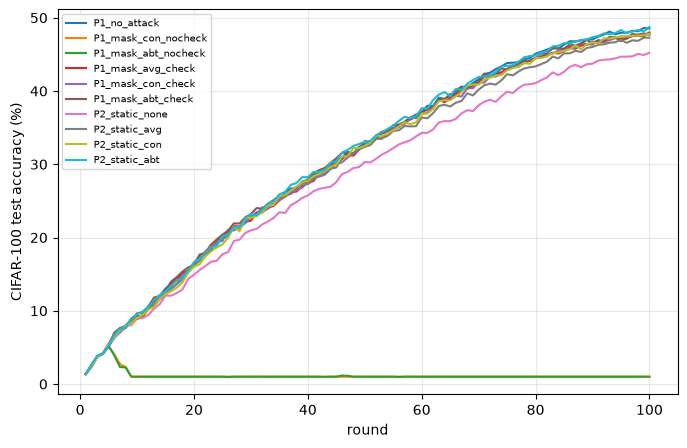

saved to C:\Users\Ahmad\Desktop\Implementation\Results\ABT_journal_CIFAR100


In [ ]:
# ===== Cell 13: results table (mean +- std over seeds) and accuracy plot =====
import matplotlib.pyplot as plt


def load_hist(run_name):
    with open(os.path.join(OUT_DIR, run_name, 'history.json')) as f:
        return json.load(f)['history']


def collect(name):
    out = []
    for sd in (0, 1, 2, 3, 4):
        try:
            h = load_hist(f'{name}_s{sd}')
        except FileNotFoundError:
            continue
        if h and h[-1]['round'] == BASE['rounds']:          # only finished runs
            out.append(summarize(h))
    return out


def ms(xs, k=1.0):
    xs = [x * k for x in xs]
    return f"{np.mean(xs):.2f} ± {np.std(xs):.2f}" if len(xs) > 1 else (f"{xs[0]:.2f}" if xs else "-")


lines = ['| Experiment | Final acc (%) | Top-5 (%) | Weight on attackers (%) | Benign excluded (%) | '
         'Detection time (s/round) | Sign check (s/round) | ABT (s/round) | Train (s/round) | Seeds |',
         '|---|---|---|---|---|---|---|---|---|---|']
for name in EXPERIMENTS:
    S = collect(name)
    if not S:
        continue
    g = lambda k: [s[k] for s in S]
    top5 = [load_hist(f'{name}_s{sd}')[-1]['top5'] for sd in range(5)
            if os.path.isfile(os.path.join(OUT_DIR, f'{name}_s{sd}', 'history.json'))][:len(S)]
    lines.append(f"| {name} | {ms(g('final_acc'))} | {ms(top5)} | {ms(g('mal_weight'), 100)} | "
                 f"{ms(g('benign_excluded'), 100)} | {ms(g('t_detect'))} | {ms(g('t_sign'))} | {ms(g('t_abt'))} | "
                 f"{ms(g('t_train'))} | {len(S)} |")
table = '\n'.join(lines)
print(table)
with open(os.path.join(OUT_DIR, 'summary_cifar100.md'), 'w', encoding='utf-8') as f:
    f.write(table + '\n')

plt.figure(figsize=(8, 5))
for name in EXPERIMENTS:
    try:
        h = load_hist(f'{name}_s0')
    except FileNotFoundError:
        continue
    plt.plot([r['round'] for r in h], [r['acc'] for r in h], label=name)
plt.xlabel('round'); plt.ylabel('CIFAR-100 test accuracy (%)'); plt.grid(alpha=.3); plt.legend(fontsize=7)
plt.savefig(os.path.join(OUT_DIR, 'cifar100_accuracy_s0.png'), dpi=200, bbox_inches='tight'); plt.show()
print('saved to', OUT_DIR)
